# Task 2 — Time Series Sales Forecasting
**Dataset:** Store Sales — Time Series Forecasting (Kaggle-style dataset)

## Objective
Clean and aggregate historical sales, explore trends and seasonality, create time-based/lag/rolling features, compare forecasting models using a chronological holdout, and forecast future sales.

**Forecasting unit:** total sales across all stores and product families per day. This creates one consistent daily time series and keeps the notebook practical to run on the large raw dataset. The test split is the final 90 observed days; the future forecast covers dates present in the provided `test.csv` (if available).

> Important: the competition test file has no sales labels. Metrics are therefore calculated only on a held-out section of `train.csv`; future forecasts cannot be evaluated until actual sales become available.

## 1. Import libraries and load data
Place the provided ZIP file in the same folder as this notebook. The code also searches the current working directory for a matching ZIP.

In [1]:
from pathlib import Path
import zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 5)

zip_candidates = list(Path(".").glob("store-sales-time-series-forecasting*.zip"))
if not zip_candidates:
    zip_candidates = list(Path("/mnt/data").glob("store-sales-time-series-forecasting*.zip"))
if not zip_candidates:
    raise FileNotFoundError("Put the supplied store-sales-time-series-forecasting ZIP next to this notebook.")
ZIP_PATH = zip_candidates[0]
print("Using dataset:", ZIP_PATH.resolve())

with zipfile.ZipFile(ZIP_PATH) as zf:
    train = pd.read_csv(zf.open("train.csv"), parse_dates=["date"])
    test = pd.read_csv(zf.open("test.csv"), parse_dates=["date"])
    stores = pd.read_csv(zf.open("stores.csv"))
    oil = pd.read_csv(zf.open("oil.csv"), parse_dates=["date"])
    holidays = pd.read_csv(zf.open("holidays_events.csv"), parse_dates=["date"])
    transactions = pd.read_csv(zf.open("transactions.csv"), parse_dates=["date"])

print("Train shape:", train.shape, "| Test shape:", test.shape)
display(train.head())

Using dataset: /mnt/data/store-sales-time-series-forecasting (1).zip


Train shape: (3000888, 6) | Test shape: (28512, 5)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## 2. Data cleaning and daily aggregation
- Parse dates and sort chronologically.
- Check missing values, duplicate rows, and sales values.
- Aggregate product/store records into daily total sales.
- Reindex to a complete daily calendar so missing dates are visible; interpolate only missing **target dates** if any occur.

In [2]:
# Basic validation
print("Date range:", train["date"].min().date(), "to", train["date"].max().date())
print("Duplicate rows:", train.duplicated().sum())
print("Missing values by column:")
display(train.isna().sum().rename("missing_count").to_frame())
print("Negative sales rows:", int((train["sales"] < 0).sum()))
print("Zero sales rows:", int((train["sales"] == 0).sum()))

train = train.drop_duplicates().copy()
train["date"] = pd.to_datetime(train["date"], errors="coerce")
train["sales"] = pd.to_numeric(train["sales"], errors="coerce")
train = train.dropna(subset=["date", "sales"])
# Negative sales are retained if present because returns/adjustments can be legitimate.
daily = train.groupby("date", as_index=True)["sales"].sum().sort_index().to_frame()
full_index = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(full_index)
daily.index.name = "date"
missing_target_days = int(daily["sales"].isna().sum())
if missing_target_days:
    daily["sales"] = daily["sales"].interpolate(method="time").ffill().bfill()
print(f"Daily observations: {len(daily):,}")
print(f"Missing calendar days filled/interpolated: {missing_target_days}")
display(daily.head())
display(daily.describe().T)

Date range: 2013-01-01 to 2017-08-15


Duplicate rows: 0
Missing values by column:


,missing_count
id,0
date,0
store_nbr,0
family,0
sales,0
onpromotion,0


Negative sales rows: 0
Zero sales rows: 939130


Daily observations: 1,688
Missing calendar days filled/interpolated: 4


,sales
date,
2013-01-01,2511.618999
2013-01-02,496092.417944
2013-01-03,361461.231124
2013-01-04,354459.677093
2013-01-05,477350.121229


,count,mean,std,min,25%,50%,75%,max
sales,1688.0,638189.986459,234741.367646,2511.618999,443170.555808,632832.884611,786699.268112,1.463084e+06


## 3. Exploratory data analysis (EDA)
Look for long-term trend, weekly/yearly patterns, distribution, and unusual daily observations. A rolling mean smooths short-term noise.

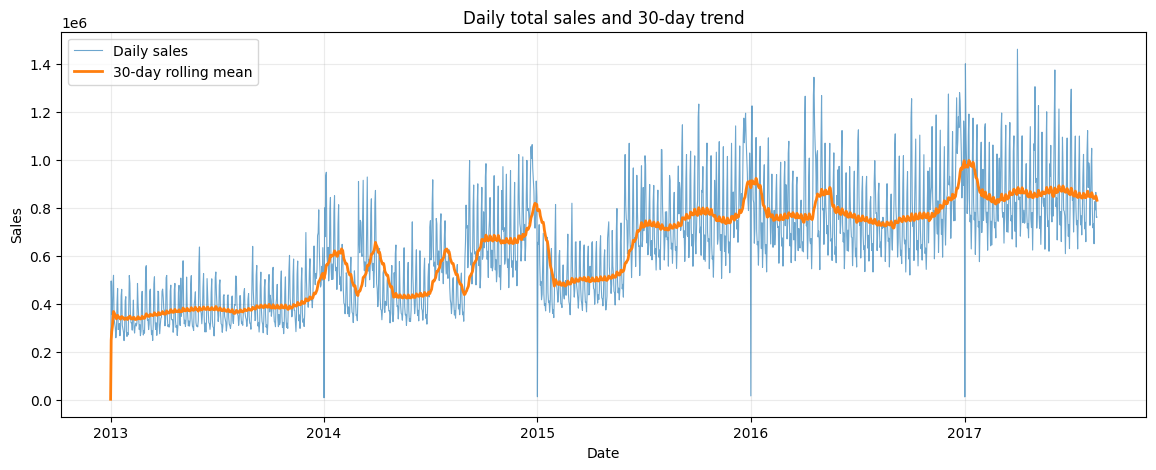

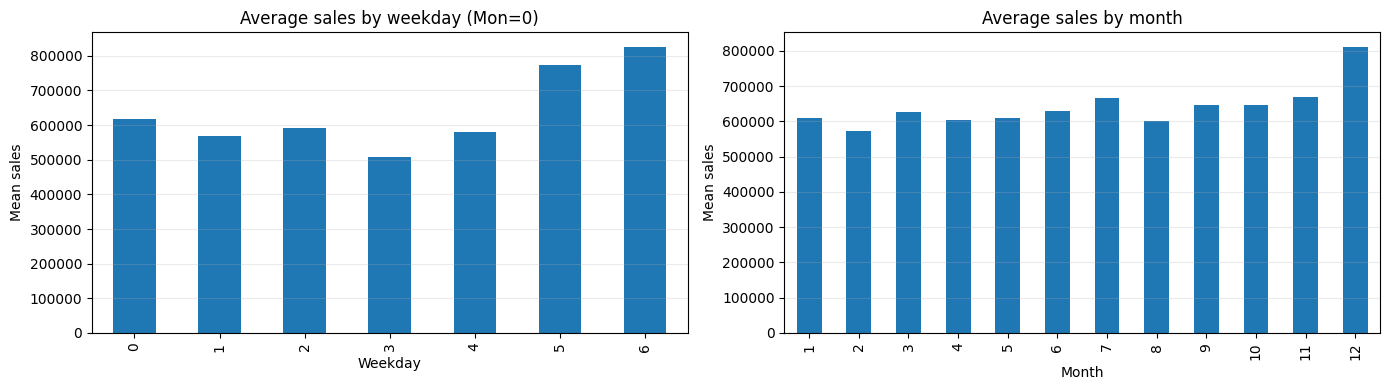

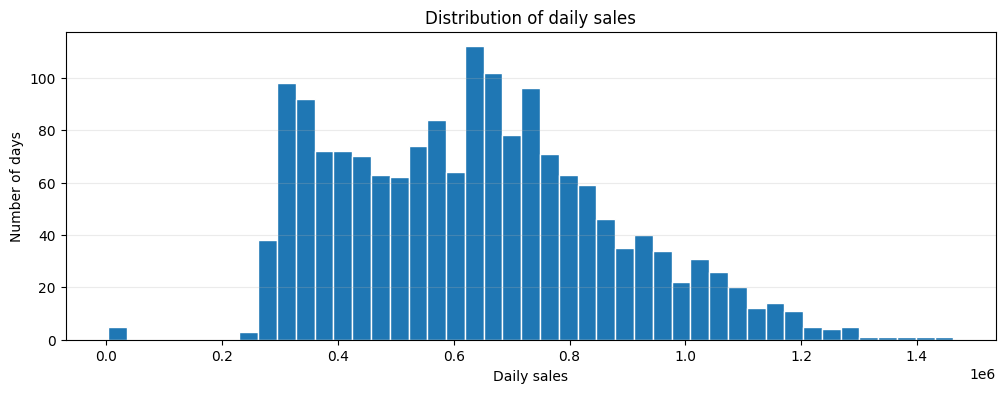

In [3]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily.index, daily["sales"], linewidth=0.8, alpha=0.65, label="Daily sales")
ax.plot(daily.index, daily["sales"].rolling(30, min_periods=1).mean(), linewidth=2, label="30-day rolling mean")
ax.set(title="Daily total sales and 30-day trend", xlabel="Date", ylabel="Sales")
ax.legend()
ax.grid(alpha=.25)
plt.show()

daily["day_of_week"] = daily.index.dayofweek
daily["month"] = daily.index.month
daily["year"] = daily.index.year
dow_avg = daily.groupby("day_of_week")["sales"].mean()
month_avg = daily.groupby("month")["sales"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
dow_avg.plot(kind="bar", ax=axes[0])
axes[0].set(title="Average sales by weekday (Mon=0)", xlabel="Weekday", ylabel="Mean sales")
month_avg.plot(kind="bar", ax=axes[1])
axes[1].set(title="Average sales by month", xlabel="Month", ylabel="Mean sales")
for ax in axes: ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(daily["sales"], bins=45, edgecolor="white")
ax.set(title="Distribution of daily sales", xlabel="Daily sales", ylabel="Number of days")
ax.grid(axis="y", alpha=.25)
plt.show()

### Unusual observations
Use a robust IQR rule on daily sales to flag unusually low/high dates. These are review candidates, not automatically errors: holidays, promotions, store closures, and events can create legitimate spikes.

In [4]:
q1, q3 = daily["sales"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = daily.loc[(daily["sales"] < lower) | (daily["sales"] > upper), ["sales"]].copy()
outliers["day_name"] = outliers.index.day_name()
print(f"IQR bounds: {lower:,.0f} to {upper:,.0f}")
print(f"Flagged unusual dates: {len(outliers)} ({len(outliers)/len(daily):.1%} of days)")
display(outliers.sort_values("sales", ascending=False).head(10))

IQR bounds: -72,123 to 1,301,992
Flagged unusual dates: 5 (0.3% of days)


,sales,day_name
date,,
2017-04-01,1.463084e+06,Saturday
2017-01-02,1.402306e+06,Monday
2017-06-04,1.376512e+06,Sunday
2016-04-18,1.345921e+06,Monday
2017-05-01,1.306699e+06,Monday


## 4. Feature engineering
Features include calendar effects, cyclical month/week encodings, previous-day/week/month sales, and rolling statistics. Rolling features are shifted by one day so the current target is never included in its own predictors.

In [5]:
def make_features(series):
    frame = pd.DataFrame(index=series.index)
    frame["sales"] = series.astype(float)
    idx = frame.index
    frame["dayofweek"] = idx.dayofweek
    frame["day"] = idx.day
    frame["month"] = idx.month
    frame["quarter"] = idx.quarter
    frame["year"] = idx.year
    frame["dayofyear"] = idx.dayofyear
    frame["weekofyear"] = idx.isocalendar().week.astype(int)
    frame["is_weekend"] = (idx.dayofweek >= 5).astype(int)
    frame["dow_sin"] = np.sin(2*np.pi*idx.dayofweek/7)
    frame["dow_cos"] = np.cos(2*np.pi*idx.dayofweek/7)
    frame["month_sin"] = np.sin(2*np.pi*idx.month/12)
    frame["month_cos"] = np.cos(2*np.pi*idx.month/12)
    for lag in [1, 7, 14, 28, 35]:
        frame[f"lag_{lag}"] = frame["sales"].shift(lag)
    shifted = frame["sales"].shift(1)
    for window in [7, 14, 28]:
        frame[f"rolling_mean_{window}"] = shifted.rolling(window).mean()
        frame[f"rolling_std_{window}"] = shifted.rolling(window).std()
    return frame

features = make_features(daily["sales"]).dropna()
display(features.head())
print("Model feature count:", features.shape[1]-1)

,sales,dayofweek,day,month,quarter,year,dayofyear,weekofyear,is_weekend,dow_sin,dow_cos,month_sin,month_cos,lag_1,lag_7,lag_14,lag_28,lag_35,rolling_mean_7,rolling_std_7,rolling_mean_14,rolling_std_14,rolling_mean_28,rolling_std_28
date,,,,,,,,,,,,,,,,,,,,,,,,
2013-02-05,321245.839130,1,5,2,1,2013,36,6,0,0.781831,0.623490,0.866025,0.5,344308.715017,264488.818076,296214.728983,318347.777981,2511.618999,362248.459470,103870.904953,341582.342171,88142.393087,339245.232912,78658.671042
2013-02-06,321538.177149,2,6,2,1,2013,37,6,0,0.974928,-0.222521,0.866025,0.5,321245.839130,281061.127052,283258.453032,302530.809018,496092.417944,370356.605335,96952.791397,343370.278610,87402.102582,339348.735096,78632.057102
2013-02-07,290807.530973,3,7,2,1,2013,38,6,0,0.433884,-0.900969,0.866025,0.5,321538.177149,271254.217996,247245.690995,258982.003049,361461.231124,376139.041063,91810.096672,346104.544618,85963.856491,340027.569672,78384.088603
2013-02-08,347441.789912,4,8,2,1,2013,39,6,0,-0.433884,-0.900969,0.866025,0.5,290807.530973,369402.055266,290022.771930,289737.685085,354459.677093,378932.371489,88318.160407,349216.104617,82841.991209,341164.195669,77389.782789
2013-02-09,416176.279075,5,9,2,1,2013,40,6,1,-0.974928,-0.222521,0.866025,0.5,347441.789912,518887.462705,413799.767975,403258.212011,477350.121229,375795.190724,89099.683150,353317.463044,81088.813219,343225.056556,76735.143580


Model feature count: 23


## 5. Chronological train-test split and metrics
The last 90 days are held out as test data. No random shuffle is used. Models:
1. **Seasonal naive:** predicts sales from the same weekday one week earlier.
2. **Random Forest:** learns non-linear patterns from calendar, lag, and rolling features.

MAE and RMSE are reported in sales units. MAPE is included with zero actuals excluded to avoid division by zero.

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

HORIZON = 90
split_date = features.index[-HORIZON]
train_feat = features.loc[features.index < split_date]
test_feat = features.loc[features.index >= split_date]
feature_cols = [c for c in features.columns if c != "sales"]
X_train, y_train = train_feat[feature_cols], train_feat["sales"]
X_test, y_test = test_feat[feature_cols], test_feat["sales"]

def score_forecast(y_true, y_pred, name):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    nonzero = y_true != 0
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAPE (%)": (np.mean(np.abs((y_true[nonzero]-y_pred[nonzero])/y_true[nonzero]))*100 if nonzero.any() else np.nan)
    }

# Weekly seasonal naive forecast
naive_pred = daily["sales"].reindex(test_feat.index - pd.Timedelta(days=7)).to_numpy()
# Guard against any missing source dates
if np.isnan(naive_pred).any():
    naive_pred = np.array([daily.loc[d-pd.Timedelta(days=7), "sales"] for d in test_feat.index])

rf = RandomForestRegressor(
    n_estimators=180, max_depth=18, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

results = pd.DataFrame([
    score_forecast(y_test, naive_pred, "Seasonal naive (7-day)"),
    score_forecast(y_test, rf_pred, "Random Forest")
]).set_index("Model").sort_values("RMSE")
display(results.style.format({"MAE":"{:,.2f}", "RMSE":"{:,.2f}", "MAPE (%)":"{:.2f}"}))
print("Training period:", train_feat.index.min().date(), "to", train_feat.index.max().date())
print("Testing period: ", test_feat.index.min().date(), "to", test_feat.index.max().date())

,MAE,RMSE,MAPE (%)
Model,,,
Random Forest,"50,365.01","71,000.13",5.58
Seasonal naive (7-day),"93,934.86","122,634.70",10.47


Training period: 2013-02-05 to 2017-05-17
Testing period:  2017-05-18 to 2017-08-15


## 6. Actual vs predicted

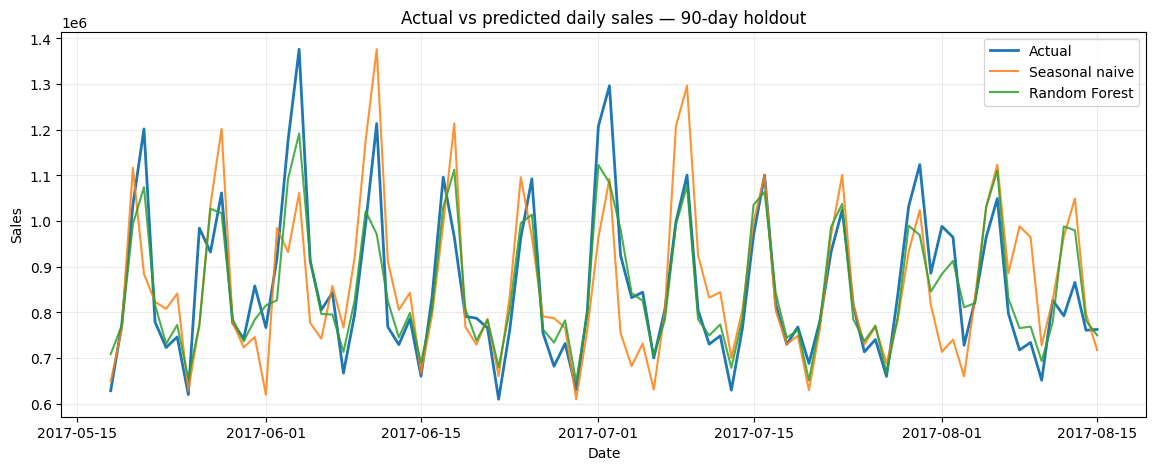

Best model by RMSE: Random Forest


In [7]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test.index, y_test.values, label="Actual", linewidth=2)
ax.plot(y_test.index, naive_pred, label="Seasonal naive", alpha=.85)
ax.plot(y_test.index, rf_pred, label="Random Forest", alpha=.85)
ax.set(title="Actual vs predicted daily sales — 90-day holdout", xlabel="Date", ylabel="Sales")
ax.legend()
ax.grid(alpha=.25)
plt.show()

best_model_name = results.index[0]
print("Best model by RMSE:", best_model_name)

## 7. Forecast future sales
The supplied `test.csv` dates begin after the historical training period. Because future sales lags are unknown, the selected machine-learning model is used recursively: each predicted day is appended to the series and becomes available as a lag for the next day. This is a practical baseline, and uncertainty will increase farther into the future.

In [8]:
# Fit a final Random Forest on all available engineered training rows.
final_rf = RandomForestRegressor(
    n_estimators=180, max_depth=18, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)
final_rf.fit(features[feature_cols], features["sales"])

future_dates = pd.DatetimeIndex(sorted(test["date"].dropna().unique()))
if len(future_dates) == 0:
    future_dates = pd.date_range(daily.index.max()+pd.Timedelta(days=1), periods=30, freq="D")

history = daily["sales"].copy()
future_predictions = []
for dt in future_dates:
    # Ensure contiguous dates through each forecast date; if the test dates have gaps,
    # still create features on the requested date using all prior known/predicted values.
    combined_index = pd.date_range(history.index.min(), dt, freq="D")
    history = history.reindex(combined_index)
    if history.iloc[:-1].isna().any():
        history = history.ffill()
    temp = make_features(history)
    row = temp.loc[[dt], feature_cols]
    if row.isna().any(axis=None):
        # Should only occur if the series has fewer than 35 historical values.
        row = row.fillna(method="bfill").fillna(0)
    pred = float(final_rf.predict(row)[0])
    future_predictions.append(pred)
    history.loc[dt] = pred

forecast = pd.DataFrame({"date": future_dates, "forecast_sales": future_predictions})
display(forecast.head(10).style.format({"forecast_sales":"{:,.2f}"}))
print(f"Forecast horizon: {len(forecast)} days ({forecast['date'].min().date()} to {forecast['date'].max().date()})")
print(f"Forecast total sales: {forecast['forecast_sales'].sum():,.0f}")

,date,forecast_sales
0,2017-08-16 00:00:00,"767,759.59"
1,2017-08-17 00:00:00,"696,015.55"
2,2017-08-18 00:00:00,"780,198.14"
3,2017-08-19 00:00:00,"898,088.22"
4,2017-08-20 00:00:00,"953,984.54"
5,2017-08-21 00:00:00,"767,288.28"
6,2017-08-22 00:00:00,"720,587.96"
7,2017-08-23 00:00:00,"755,509.08"
8,2017-08-24 00:00:00,"673,794.66"
9,2017-08-25 00:00:00,"809,568.65"


Forecast horizon: 16 days (2017-08-16 to 2017-08-31)
Forecast total sales: 12,814,726


## 8. Forecast visualization and seasonal observations

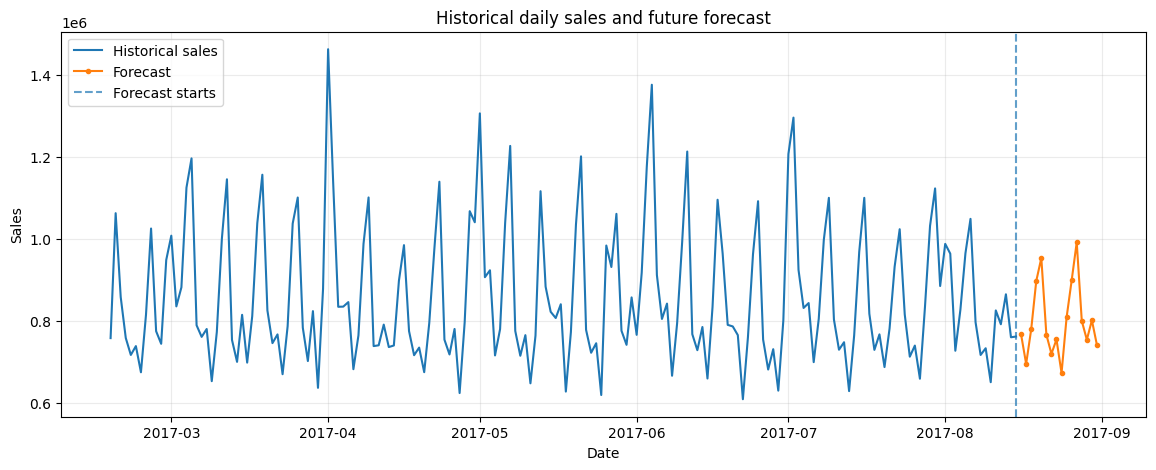

,average_forecast_sales
weekday,
Sunday,973258.177987
Saturday,898865.405918
Friday,794883.393828
Monday,784064.954644
Wednesday,775222.868888
Tuesday,737735.320051
Thursday,703814.398766


Historical average sales by weekday:


,average_sales
day_of_week,
6,826523.46
5,772205.59
0,617542.71
2,593047.26
4,581381.95
1,569926.09
3,506986.10


In [9]:
fig, ax = plt.subplots(figsize=(14, 5))
recent = daily.iloc[-180:]
ax.plot(recent.index, recent["sales"], label="Historical sales", linewidth=1.5)
ax.plot(forecast["date"], forecast["forecast_sales"], label="Forecast", marker="o", markersize=3)
ax.axvline(daily.index.max(), linestyle="--", alpha=.7, label="Forecast starts")
ax.set(title="Historical daily sales and future forecast", xlabel="Date", ylabel="Sales")
ax.legend()
ax.grid(alpha=.25)
plt.show()

forecast_view = forecast.copy()
forecast_view["weekday"] = forecast_view["date"].dt.day_name()
forecast_view["month"] = forecast_view["date"].dt.month_name()
display(forecast_view.groupby("weekday", sort=False)["forecast_sales"].mean().sort_values(ascending=False).rename("average_forecast_sales").to_frame())
print("Historical average sales by weekday:")
display(dow_avg.sort_values(ascending=False).rename("average_sales").to_frame().round(2))

## 9. Final observations and conclusion
The notebook outputs above provide the data-driven findings for this dataset:
- The daily time-series chart shows the overall sales trajectory and longer-term changes.
- Weekday and month averages reveal calendar-related seasonality; compare the bars to identify consistently stronger/weaker periods.
- IQR-flagged dates are unusual observations worth checking against holidays, promotions, or operational events rather than deleting automatically.
- The holdout metrics compare a simple weekly seasonal baseline against a machine-learning model. Prefer the model with the lowest RMSE, while also checking MAE and MAPE.
- Forecasts are point estimates, not guarantees. Recursive forecasts can drift because predicted values are reused as lag features; use prediction intervals and external future information (planned promotions/holidays) for a production system.

**Limitations:** this version models total daily sales, does not explicitly model store/product-family differences, and does not include future promotion/holiday variables. A next improvement is to train separate store-family models or use a global model with store/family identifiers and known future promotions.